# RF Intrusion CNN v3/v4 Training and Evaluation

This cleaned notebook preserves the final model sequence. CNN v3 is intentionally weak for a controlled failed CI/CD gate; CNN v4 is the promoted, improved model. Existing v1/v2 artifacts are read only. Run AWS-mutating cells only after approval.

## 1. Local setup and data

Run in the TensorFlow Docker container from the SageMaker work folder. The existing curated 40/10/10/40 split is unchanged.

## Docker Desktop: run TensorFlow locally with the NVIDIA GPU

1. Install Docker Desktop for Windows, use the **WSL 2 based engine**, and make sure WSL is current (`wsl --update`). GPU passthrough requires an NVIDIA GPU, a current NVIDIA Windows driver that supports WSL 2, and Docker Desktop running Linux containers.
2. In PowerShell, change to this project folder and confirm Docker can see the GPU:

```powershell
docker run --rm --gpus all ubuntu nvidia-smi
```

3. Start Jupyter in the TensorFlow GPU image, mounting the project into `/workspace`:

```powershell
docker run --rm --gpus all -p 8888:8888 -v "${PWD}:/workspace" -w /workspace tensorflow/tensorflow:latest-gpu-jupyter
```

4. Open the tokenized `http://127.0.0.1:8888/...` URL printed by Jupyter, then open this notebook. Run the setup cell and verify that `tf.config.list_physical_devices('GPU')` is non-empty before training. The container is removed when stopped; models and metrics persist because they are written to the mounted project folder.

If GPU detection fails, update WSL and the NVIDIA driver, confirm Docker Desktop is using WSL 2, then rerun the `nvidia-smi` container check before running TensorFlow.

In [1]:
%pip install -q pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json, random, tarfile
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
WORKDIR = Path.cwd()
DATA_ROOT = WORKDIR / 'data' / 'kaggle_assignment_split' / 'rf_assignment_split'
ARTIFACT_DIR = WORKDIR / 'models' / 'tensorflow_training'
REGISTRY_PACKAGE_DIR = WORKDIR / 'artifacts' / 'registry_packages'
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
assert DATA_ROOT.exists() and ARTIFACT_DIR.exists()
print('TensorFlow:', tf.__version__)
print('Data root:', DATA_ROOT)

I0000 00:00:1791605972.981548      38 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791605973.240380      38 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791605975.005058      38 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
Data root: /workspace/data/kaggle_assignment_split/rf_assignment_split


In [3]:
train_dir, validation_dir, test_dir = DATA_ROOT / 'train', DATA_ROOT / 'validation', DATA_ROOT / 'test'
class_names = sorted(path.name for path in train_dir.iterdir() if path.is_dir())
EXPECTED_CLASSES = ['Benign', 'Broadband_Jam', 'Human', 'Machine', 'Narrowband_Jam', 'Wildlife']
assert class_names == EXPECTED_CLASSES, class_names

def make_dataset(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(path, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', color_mode='rgb', shuffle=shuffle, seed=SEED if shuffle else None).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_dir, True)
validation_ds = make_dataset(validation_dir, False)
test_ds = make_dataset(test_dir, False)
print('Classes:', class_names)

Found 9600 files belonging to 6 classes.


W0000 00:00:1791605976.993245      38 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791605977.001984      38 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791605977.293145      38 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13153 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5080, pci bus id: 0000:01:00.0, compute capability: 12.0a


Found 2400 files belonging to 6 classes.
Found 2400 files belonging to 6 classes.
Classes: ['Benign', 'Broadband_Jam', 'Human', 'Machine', 'Narrowband_Jam', 'Wildlife']


In [4]:
def evaluate_and_save(model, version, history):
    probabilities = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    metrics = {'model_version': version, 'created_utc': datetime.now(timezone.utc).isoformat(), 'input_shape': [128,128,3], 'class_names': class_names, 'evaluation': {'test_accuracy': float(accuracy_score(y_true,y_pred)), 'macro_precision': float(macro_precision), 'macro_recall': float(macro_recall), 'macro_f1': float(macro_f1), 'classification_report': classification_report(y_true,y_pred,target_names=class_names,output_dict=True,zero_division=0), 'confusion_matrix': confusion_matrix(y_true,y_pred).tolist()}, 'history': {key:[float(v) for v in values] for key,values in history.history.items()}}
    model_path = ARTIFACT_DIR / f'rf_intrusion_cnn_{version}.keras'
    metrics_path = ARTIFACT_DIR / f'rf_intrusion_cnn_{version}_metrics.json'
    model.save(model_path); metrics_path.write_text(json.dumps(metrics, indent=2))
    return metrics, model_path

v2_metadata = json.loads((ARTIFACT_DIR / 'improved_cnn_rf_intrusion_v2_metadata.json').read_text())
V2_ACCURACY = float(v2_metadata['evaluation']['test_accuracy'])
V2_MACRO_F1 = float(v2_metadata['evaluation']['macro_f1'])
print(f'CNN v2 baseline — accuracy: {V2_ACCURACY:.4f}, macro F1: {V2_MACRO_F1:.4f}')

CNN v2 baseline — accuracy: 0.8633, macro F1: 0.8588


## 2. CNN v3: controlled failure model

V3 is intentionally shallow and limited to three epochs. Its measured macro F1 was 0.5931, below v2. Use a macro-F1 gate of 0.80 to demonstrate the intentionally failed pipeline path. Its artifact is retained but must not be approved.

In [5]:
def build_v3():
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(128,128,3)), tf.keras.layers.Rescaling(1./255), tf.keras.layers.Conv2D(16,3,activation='relu',padding='same'), tf.keras.layers.MaxPooling2D(), tf.keras.layers.Conv2D(32,3,activation='relu',padding='same'), tf.keras.layers.GlobalAveragePooling2D(), tf.keras.layers.Dense(6,activation='softmax')], name='rf_intrusion_cnn_v3_controlled_weak')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Existing v3 artifacts are retained. Uncomment only to retrain.
# v3_model = build_v3()
# v3_history = v3_model.fit(train_ds, validation_data=validation_ds, epochs=3, verbose=1)
# v3_metrics, v3_path = evaluate_and_save(v3_model, 'v3', v3_history)

## 3. CNN v4: promoted architecture

V4 keeps v2's 32 → 64 → 128 → 256 filter progression, but uses **two 3×3 convolution layers per stage before MaxPool**. Batch normalization and ReLU follow every convolution. Light dropout is applied only after later stages: 0.05, 0.08, and 0.10. The classifier uses global average pooling, Dense(256), Dropout(0.28), and six-class softmax.

This removes unsuccessful approaches: no spatial dropout, random translation, AdamW, label smoothing, or aggressive augmentation. Adam begins at 0.0002, with early stopping and learning-rate reduction. Final v4 achieved 0.8875 accuracy and 0.8865 macro F1, outperforming v2's 0.8633 and 0.8588.

In [6]:
def conv_block(x, filters, dropout_rate=0.0):
    for _ in range(2):
        x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    return tf.keras.layers.Dropout(dropout_rate)(x) if dropout_rate else x

def build_v4():
    inputs = tf.keras.Input(shape=(128,128,3), name='spectrogram')
    x = tf.keras.layers.Rescaling(1./255)(inputs)
    x = conv_block(x, 32)
    x = conv_block(x, 64, 0.05)
    x = conv_block(x, 128, 0.08)
    x = conv_block(x, 256, 0.10)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.28)(x)
    outputs = tf.keras.layers.Dense(len(class_names), activation='softmax', name='class_probabilities')(x)
    model = tf.keras.Model(inputs, outputs, name='rf_intrusion_cnn_v4')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=2e-4), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# Existing final v4 artifacts are retained. Uncomment only to retrain.
# v4_model = build_v4()
# callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=2, min_lr=1e-6, verbose=1)]
# v4_history = v4_model.fit(train_ds, validation_data=validation_ds, epochs=30, callbacks=callbacks, verbose=1)
# v4_metrics, v4_path = evaluate_and_save(v4_model, 'v4', v4_history)

## 4. Final v2 versus v4 validation

V4 is the only v4 artifact intended for Model Registry promotion.

In [7]:
v4_metrics = json.loads((ARTIFACT_DIR / 'rf_intrusion_cnn_v4_metrics.json').read_text())
v4_evaluation = v4_metrics['evaluation']
comparison = pd.DataFrame([{'version':'v2','accuracy':V2_ACCURACY,'macro_f1':V2_MACRO_F1}, {'version':'v4','accuracy':v4_evaluation['test_accuracy'],'macro_f1':v4_evaluation['macro_f1']}])
display(comparison.style.format({'accuracy':'{:.4f}', 'macro_f1':'{:.4f}'}))
assert v4_evaluation['macro_f1'] > V2_MACRO_F1, 'Final v4 must beat v2 before approval.'
print('PASS: Final CNN v4 may be registered as Approved.')

,version,accuracy,macro_f1
0,v2,0.8633,0.8588
1,v4,0.8875,0.8865


PASS: Final CNN v4 may be registered as Approved.


## 5. Local v3 versus v4 class-level evaluation

This local-only section reloads the saved v3 and v4 artifacts and evaluates both on the unchanged test split. It displays per-class precision, recall, and F1-score, plus side-by-side confusion matrices. Run sections 1 and 5 after the notebook kernel starts; it does not use AWS or modify the saved model artifacts.

I0000 00:00:1791605997.740111     191 service.cc:153] XLA service 0x76926802c9d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791605997.740151     191 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5080, Compute Capability 12.0a (Driver: 13.4.0; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.8.0)
I0000 00:00:1791605997.804053     191 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791605997.865335     191 cuda_dnn.cc:461] Loaded cuDNN version 90800
I0000 00:00:1791606007.512363     191 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



CNN v3 (controlled failure): precision, recall, and F1 by class


,precision,recall,f1_score,support
Benign,0.6705,0.5900,0.6277,400
Broadband_Jam,0.5593,0.6250,0.5903,400
Human,0.6929,0.9250,0.7923,400
Machine,0.6019,0.1625,0.2559,400
Narrowband_Jam,0.6540,0.7750,0.7094,400
Wildlife,0.5320,0.6450,0.5831,400



CNN v4 (promoted): precision, recall, and F1 by class


,precision,recall,f1_score,support
Benign,0.7413,0.8525,0.7930,400
Broadband_Jam,0.9950,0.9975,0.9963,400
Human,0.9494,0.9375,0.9434,400
Machine,0.7500,0.6450,0.6935,400
Narrowband_Jam,1.0000,0.9950,0.9975,400
Wildlife,0.8930,0.8975,0.8953,400


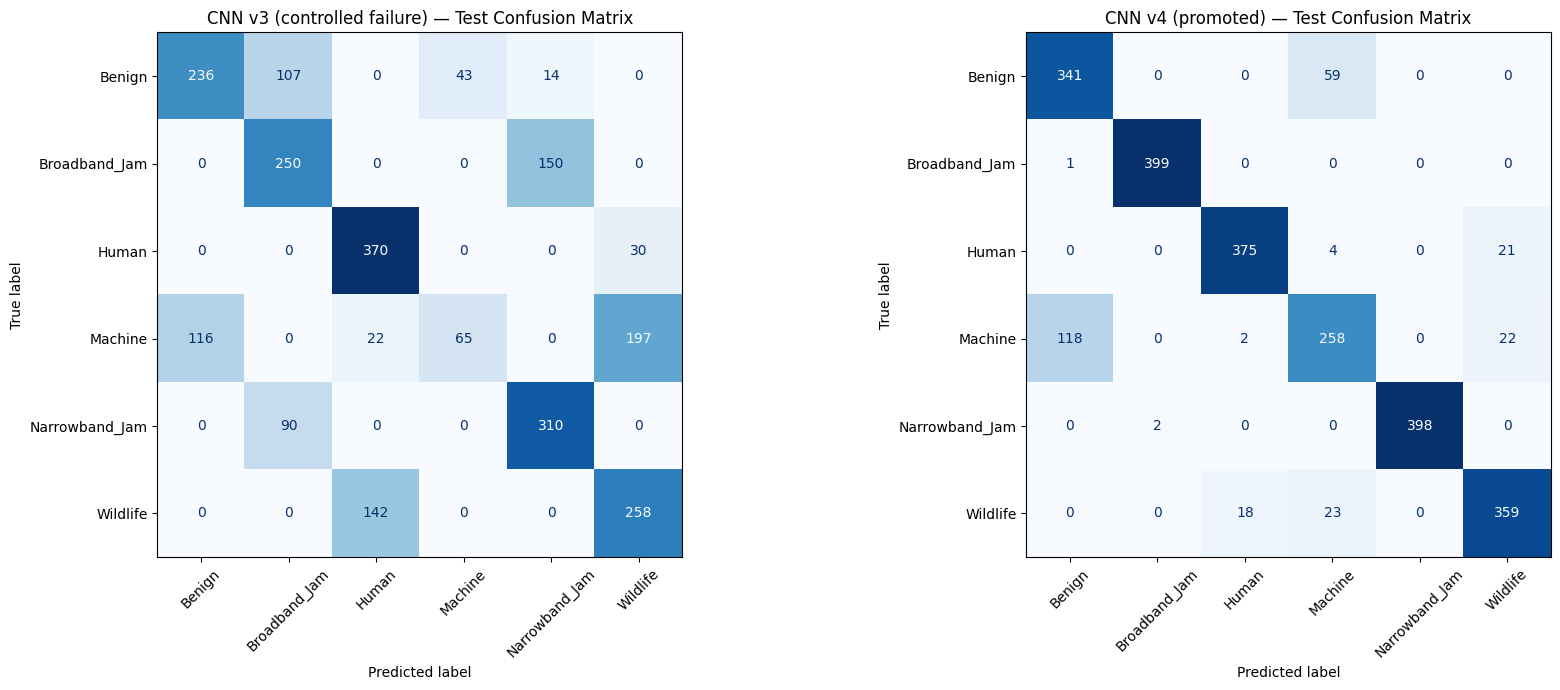

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

MODEL_PATHS = {
    'CNN v3 (controlled failure)': ARTIFACT_DIR / 'rf_intrusion_cnn_v3.keras',
    'CNN v4 (promoted)': ARTIFACT_DIR / 'rf_intrusion_cnn_v4.keras',
}
assert all(path.exists() for path in MODEL_PATHS.values()), MODEL_PATHS

def evaluate_saved_model(model_path):
    saved_model = tf.keras.models.load_model(model_path)
    probabilities = saved_model.predict(test_ds, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)
    y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in test_ds])
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
    per_class = pd.DataFrame(report).T.loc[class_names, ['precision', 'recall', 'f1-score', 'support']].rename(columns={'f1-score': 'f1_score'})
    return y_true, y_pred, per_class

evaluations = {label: evaluate_saved_model(path) for label, path in MODEL_PATHS.items()}
for label, (_, _, per_class) in evaluations.items():
    print(f'\n{label}: precision, recall, and F1 by class')
    display(per_class.style.format({'precision': '{:.4f}', 'recall': '{:.4f}', 'f1_score': '{:.4f}', 'support': '{:.0f}'}))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for axis, (label, (y_true, y_pred, _)) in zip(axes, evaluations.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(ax=axis, cmap='Blues', values_format='d', colorbar=False)
    axis.set_title(f'{label} — Test Confusion Matrix')
    axis.tick_params(axis='x', labelrotation=45)
plt.tight_layout()
plt.show()